# pyTDI A/E to Coronagraphic Kappa + HDBSCAN

This notebook is the end-to-end reference workflow for the pyTDI-only coronagraphic clustering path.

Pipeline stages:

1. Create a minimal one-SMBHB catalog and config.
2. Simulate noisy LISA six-link data for that SMBHB.
3. Compute second-generation Michelson `X,Y,Z` and orthogonal `A,E,T` with `pyTDI`.
4. Transform pyTDI `A,E` into multi-resolution WDM maps.
5. Select the top WDM-noise-normalized pixels.
6. Compute coronagraphic `kappa` on only those selected pixels using the six-link data.
7. Run HDBSCAN as a separate step on the kappa feature table.
8. Merge clusters across WDM resolutions and plot the result.

Important contract: WDM selection uses only pyTDI-computed `A,E`. The six-link data are used for the kappa/null construction, not for an internal A/E substitute.

In [1]:
from pathlib import Path
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# Make the notebook robust whether it is launched from the repo root or examples/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "scripts").exists() and (PROJECT_ROOT.parent / "scripts").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)

DEMO_ROOT = PROJECT_ROOT / "examples" / "runs" / "pytdi_coronagraphic_demo"
CONFIG = DEMO_ROOT / "config_one_smbhb.yaml"
CATALOG = DEMO_ROOT / "catalog_one_smbhb.csv"
RUNS_ROOT = DEMO_ROOT / "simulations"
SOURCE_ID = "demo_smbhb_m1e6"
WORK_DIR = RUNS_ROOT / SOURCE_ID
RUN_DIR = DEMO_ROOT / "coronagraphic" / f"{SOURCE_ID}_pytdi_kappa"

DEMO_ROOT.mkdir(parents=True, exist_ok=True)
print(f"PROJECT_ROOT = {PROJECT_ROOT}")
print(f"WORK_DIR     = {WORK_DIR}")
print(f"RUN_DIR      = {RUN_DIR}")

PROJECT_ROOT = /Users/shubhanshutiwari/IdeaProjects/LISA-TF
WORK_DIR     = /Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/simulations/demo_smbhb_m1e6
RUN_DIR      = /Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa


## 1. Create A Minimal One-SMBHB Catalog

This cell creates the catalog used by the rest of the notebook. It is intentionally one source only, so the example is self-contained and does not depend on `test-run/catalog.csv`.

The required columns are:

- `source_id,total_mass,m1,m2,q,eta`
- `distance_mpc,s1,s2,f_min_hz,iota,phi_ref,ra,dec`

In [2]:
def component_masses(total_mass, eta):
    eta = float(eta)
    if abs(eta - 0.25) < 1e-12:
        q = 1.0
    else:
        q = (1.0 - 2.0 * eta - (1.0 - 4.0 * eta) ** 0.5) / (2.0 * eta)
    m1 = float(total_mass) / (1.0 + q)
    m2 = float(total_mass) - m1
    return m1, m2, q

source = {
    "source_id": SOURCE_ID,
    "total_mass": 1.0e6,
    "eta": 0.22,
    "distance_mpc": 3000.0,
    "s1": 0.20,
    "s2": -0.10,
    "f_min_hz": 1.0e-4,
    "iota": 0.60,
    "phi_ref": 1.10,
    "ra": 0.70,
    "dec": -0.55,
}
source["m1"], source["m2"], source["q"] = component_masses(source["total_mass"], source["eta"])
ordered_cols = [
    "source_id", "total_mass", "m1", "m2", "q", "eta", "distance_mpc",
    "s1", "s2", "f_min_hz", "iota", "phi_ref", "ra", "dec",
]
catalog = pd.DataFrame([{col: source[col] for col in ordered_cols}])
catalog.to_csv(CATALOG, index=False)
CATALOG, catalog

(PosixPath('/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/catalog_one_smbhb.csv'),
          source_id  total_mass             m1             m2         q   eta  \
 0  demo_smbhb_m1e6   1000000.0  673205.080757  326794.919243  0.485431  0.22   
 
    distance_mpc   s1   s2  f_min_hz  iota  phi_ref   ra   dec  
 0        3000.0  0.2 -0.1    0.0001   0.6      1.1  0.7 -0.55  )

## 2. Create A Minimal Pipeline Config

This config is short enough for a notebook example but still produces full noisy six-link data and second-generation pyTDI `XYZ/AET`.

For a faster smoke run, reduce `science_duration_s` and `raw_half_duration_s`. For production-quality plots, keep the longer values or use the existing `test-run/config.yaml`.

In [3]:
config_text = f"""
waveform:
  raw_dt_s: 1.0
  raw_half_duration_s: 300000.0

simulation:
  dt_s: 0.1
  science_duration_s: 150000.0
  burn_in_seconds: 600.0
  orbit_dt_s: 600.0
  orbit_duration_factor: 5.0
  central_freq_hz: 281600000000000.0
  frequency_low_hz: 0.00001
  frequency_high_hz: 0.1
  tdi_generation: 2
  interpolation_order: 31
  seed: 24680

dataset:
  runs_root: {RUNS_ROOT}
  catalog_csv: {CATALOG}
"""
CONFIG.write_text(config_text, encoding="utf-8")
print(CONFIG)
print(CONFIG.read_text())

/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/config_one_smbhb.yaml

waveform:
  raw_dt_s: 1.0
  raw_half_duration_s: 300000.0

simulation:
  dt_s: 0.1
  science_duration_s: 150000.0
  burn_in_seconds: 600.0
  orbit_dt_s: 600.0
  orbit_duration_factor: 5.0
  central_freq_hz: 281600000000000.0
  frequency_low_hz: 0.00001
  frequency_high_hz: 0.1
  tdi_generation: 2
  interpolation_order: 31
  seed: 24680

dataset:
  runs_root: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/simulations
  catalog_csv: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/catalog_one_smbhb.csv



## 3. Simulate LISA Six-Link Data

This step creates the six Doppler links and the noisy `lisainstrument` output. If the products already exist, you can skip this cell.

Expected outputs under `WORK_DIR / "outputs"`:

- `six_links_gw_only.csv`
- `six_links_noisy.csv`
- `lisa_instrument_output.h5`
- `gws.h5`

For a full fresh run of one source, run:

In [4]:
!conda run -n lisa-tf python {PROJECT_ROOT / "test-run" / "run_noisy_six_link_only.py"} \
  --config {CONFIG} \
  --catalog {CATALOG} \
  --runs-root {RUNS_ROOT} \
  --source-id {SOURCE_ID}

/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/simulations/demo_smbhb_m1e6
OEM preferred interpolation method ignored, using spline interpolation (see InterpolatedOrbits for details)
You are using an orbit file in a version that might not be fully supported
You are using an orbit file in a version that might not be fully supported
Using default set of locking beatnote frequencies might cause interferometric beatnote frequencies to fall outside the requirement range of 5..25 MHz


## 4. Compute pyTDI XYZ and AET

This is the only accepted A/E source for WDM pixel selection in this pipeline.

Expected outputs:

- `tdi_michelson_XYZ_AET.csv` for noisy `X,Y,Z,A,E,T`
- `tdi_gw_only_XYZ_AET.csv` for GW-only `X,Y,Z,A,E,T`

In [5]:
!conda run -n lisa-tf python {PROJECT_ROOT / "test-run" / "generate_tdi_from_existing_h5.py"} \
  --config {CONFIG} \
  --catalog {CATALOG} \
  --runs-root {RUNS_ROOT} \
  --source-id {SOURCE_ID} \
  --make-plots

{
  "source_id": "demo_smbhb_m1e6",
  "work_dir": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/simulations/demo_smbhb_m1e6",
  "noisy_tdi_csv": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/simulations/demo_smbhb_m1e6/outputs/tdi_michelson_XYZ_AET.csv",
  "gw_tdi_csv": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/simulations/demo_smbhb_m1e6/outputs/tdi_gw_only_XYZ_AET.csv",
  "tdi_samples": 1500000,
  "tdi_start_index": 6000,
  "noisy_x_std_hz": 4.43682481812482e-05,
  "noisy_a_std_hz": 5.736959699802781e-05,
  "gw_tdi_samples": 1500000,
  "gw_x_max_hz": 0.002127341822322548,
  "gw_a_max_hz": 0.002806263307324213
}
You are using a measurement file in a version that might not be fully supported (got '2.1.0', official support up to '2.0')
You are using a GW file in a version that might not be fully supported
You are using an orbit file in a version that might not be full

Quick sanity check: load the pyTDI noisy A/E CSV and plot a short time-domain segment.

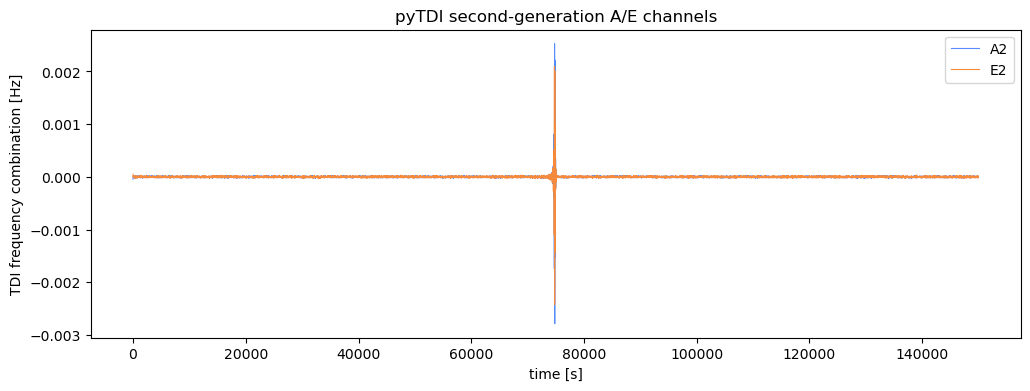

In [6]:
tdi = pd.read_csv(WORK_DIR / "outputs" / "tdi_michelson_XYZ_AET.csv")
a_col = [c for c in tdi.columns if c.startswith("A") and not c.endswith("_gw_hz")][0]
e_col = [c for c in tdi.columns if c.startswith("E") and not c.endswith("_gw_hz")][0]

ax = tdi.iloc[::100].plot(x="t_waveform", y=[a_col, e_col], figsize=(12, 4), lw=0.8)
ax.set_title("pyTDI second-generation A/E channels")
ax.set_xlabel("time [s]")
ax.set_ylabel("TDI frequency combination [Hz]")
plt.show()

## 5. WDM Selection + Kappa Scan

This step builds multi-resolution WDM maps from pyTDI `A,E`, selects the top 10% of off-source-normalized pixels, and computes kappa over a HEALPix sky grid only for those selected pixels.

Use `--skip-hdbscan` here when you want a clean separation between kappa feature generation and density clustering.

In [7]:
!conda run -n lisa-tf python -m scripts.coronagraphic_kappa_scan \
  --work-dir {WORK_DIR} \
  --output-dir {RUN_DIR} \
  --source noisy \
  --nside 4 \
  --chunk-duration-s 32768 \
  --wdm-ms 128,256,512 \
  --top-pixel-fraction 0.10 \
  --selection-normalization offsource-frequency-median \
  --offsource-edge-fraction 0.20 \
  --min-cluster-size 5 \
  --skip-hdbscan \
  --no-plots

{
  "config": {
    "work_dir": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/simulations/demo_smbhb_m1e6",
    "output_dir": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa",
    "source": "noisy",
    "nside": 4,
    "chunk_duration_s": 32768.0,
    "target_dt_s": 1.0,
    "wdm_m": 512,
    "wdm_k": 32,
    "wdm_beta_order": 6,
    "wdm_precision": 6,
    "wdm_backend": "numba",
    "top_pixels": 80,
    "freq_min_hz": 0.0001,
    "freq_max_hz": 0.1,
    "min_cluster_size": 5,
    "min_samples": null,
    "make_plots": false,
    "wdm_ms": [
      128,
      256,
      512
    ],
    "top_pixel_fraction": 0.1,
    "selection_normalization": "offsource-frequency-median",
    "offsource_edge_fraction": 0.2,
    "wdm_aet_source": "pytdi",
    "run_hdbscan": false,
    "selection_start_guard_s": 0.0,
    "selection_end_guard_s": 0.0
  },
  "mode": "multi_resolution",
  "w

The kappa scan writes candidate pixels and unclustered kappa features.

In [8]:
summary = json.loads((RUN_DIR / "summary.json").read_text())
print(json.dumps({k: summary[k] for k in ["mode", "wdm_ms", "wdm_aet_source", "run_hdbscan", "n_sky_directions"]}, indent=2))
pd.read_csv(RUN_DIR / "kappa_features_all_resolutions.csv").head()

{
  "mode": "multi_resolution",
  "wdm_ms": [
    128,
    256,
    512
  ],
  "wdm_aet_source": "pytdi",
  "run_hdbscan": false,
  "n_sky_directions": 192
}


,wdm_m,pixel_id,selection_rank,freq_idx,time_idx,freq_hz,time_s,ae_power,selection_power,selection_background,...,best_healpix,best_ra,best_dec,best_x,best_y,best_z,kappa_min_power,kappa_median_power,sky_contrast,sky_sharpness
0,128,0,1,3,126,0.011719,74808.0,0.000443,173817.716536,2.549901e-09,...,88,0.19635,0.0,0.980785,0.19509,0.0,0.0,0.000075,7.521912e+295,4.615972e+294
1,128,1,2,4,127,0.015625,74936.0,0.000407,107853.640022,3.774112e-09,...,88,0.19635,0.0,0.980785,0.19509,0.0,0.0,0.002241,2.241268e+297,1.534466e+296
2,128,2,3,2,126,0.007812,74808.0,0.000106,93149.992335,1.138496e-09,...,88,0.19635,0.0,0.980785,0.19509,0.0,0.0,0.000006,5.906572e+294,4.087565e+293
3,128,3,4,4,126,0.015625,74808.0,0.000328,86950.083582,3.774112e-09,...,88,0.19635,0.0,0.980785,0.19509,0.0,0.0,0.003130,3.129540e+297,2.219246e+296
4,128,4,5,5,127,0.019531,74936.0,0.000184,59047.558868,3.114812e-09,...,88,0.19635,0.0,0.980785,0.19509,0.0,0.0,0.013827,1.382716e+298,8.085161e+296


## 6. HDBSCAN Clustering

This step reads `kappa_features.csv` from each WDM layer and writes `pixel_clusters.csv`. It does not recompute WDM or kappa, so it is the right place to tune `min_cluster_size` and `min_samples`.

In [9]:
!conda run -n lisa-tf python -m scripts.coronagraphic_hdbscan \
  --run-dir {RUN_DIR} \
  --min-cluster-size 5

{
  "run_dir": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa",
  "outputs": [
    "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa/wdm_m_128/pixel_clusters.csv",
    "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa/wdm_m_256/pixel_clusters.csv",
    "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa/wdm_m_512/pixel_clusters.csv",
    "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa/pixel_clusters_all_resolutions.csv"
  ],
  "cluster_counts": {
    "-1": 491,
    "0": 58,
    "1": 32,
    "2": 57,
    "3": 32,
    "4": 51,
    "5": 27,
    "6": 75,
    "7": 378,
    "8": 45,
    "9": 30,
    "10": 57,
 

In [10]:
clusters = pd.read_csv(RUN_DIR / "pixel_clusters_all_resolutions.csv")
clusters["cluster"].value_counts().sort_index()

cluster
-1     491
 0      58
 1      32
 2      57
 3      32
 4      51
 5      27
 6      75
 7     378
 8      45
 9      30
 10     57
 11     33
 12     29
 13     36
 14    204
 15     29
 16     55
 17     31
 18     17
 19     18
 20     36
 21     24
 22     25
 23      9
 24      7
 25     12
 26     14
 27      8
 28      7
 29     19
Name: count, dtype: int64

## 7. Cross-Resolution Merge

The first HDBSCAN pass clusters pixels within each WDM resolution. The merge step summarizes coherent per-resolution clusters and runs a second HDBSCAN pass to group them into event candidates across resolutions.

In [11]:
!conda run -n lisa-tf python -m scripts.coronagraphic_multires_merge \
  --run-dir {RUN_DIR} \
  --min-cluster-size 2 \
  --min-resolutions 2

{
  "run_dir": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa",
  "output_dir": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa",
  "n_pixels": 1946,
  "n_coherent_pixels": 1455,
  "n_layer_clusters": 64,
  "n_hdbscan_event_clusters": 9,
  "n_multires_event_candidates": 8,
  "event_cluster_counts": {
    "-1": 567,
    "0": 128,
    "1": 58,
    "2": 697,
    "3": 49,
    "4": 66,
    "5": 53,
    "6": 119,
    "7": 70,
    "8": 139
  },
  "event_summary_csv": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa/multires_event_summary.csv",
  "merged_pixels_csv": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa/merged_pixel_clusters.csv",
  "representatives_csv": "/Users/shubhansh

In [12]:
event_summary_path = RUN_DIR / "multires_event_summary.csv"
if event_summary_path.exists():
    display(pd.read_csv(event_summary_path))
else:
    print("No merged event summary produced.")

,event_cluster,n_pixels,n_layer_clusters,n_resolutions,wdm_ms,layer_cluster_ids,passes_min_resolutions,median_time_s,time_start_s,time_stop_s,...,freq_min_hz,freq_max_hz,median_best_x,median_best_y,median_best_z,median_kappa_min_power,median_sky_contrast,median_sky_sharpness,median_event_probability,median_true_sky_sep_deg
0,0,128,11,2,"128,512","M128_c12,M128_c18,M128_c20,M128_c21,M128_c22,M...",True,80408.0,59384.0,91320.0,...,0.011719,0.097656,0.980785,0.19509,0.0,0.0,1.289169e+299,6.424422e+297,1.000000,41.697806
1,1,58,3,2,"128,512","M128_c29,M512_c16,M512_c17",True,75256.0,59896.0,91128.0,...,0.018555,0.079102,0.980785,0.19509,0.0,0.0,1.127778e+299,7.391654e+297,1.000000,41.697806
2,2,697,11,3,"128,256,512","M128_c14,M128_c15,M128_c16,M128_c19,M128_c9,M2...",True,72696.0,58808.0,91256.0,...,0.013672,0.099609,0.980785,0.19509,0.0,0.0,5.432467e+300,1.788055e+299,0.834051,41.697806
3,3,49,5,1,128,"M128_c23,M128_c24,M128_c25,M128_c26,M128_c28",False,71352.0,59192.0,88888.0,...,0.015625,0.042969,0.980785,0.19509,0.0,0.0,2.262096e+298,1.315979e+297,0.676870,41.697806
4,4,66,3,3,"128,256,512","M128_c11,M256_c5,M512_c20",True,75256.0,61048.0,91128.0,...,0.009766,0.019531,0.980785,0.19509,0.0,0.0,4.061574e+296,2.753248e+295,1.000000,41.697806
5,5,53,3,2,"256,512","M256_c10,M256_c8,M512_c11",True,78200.0,63608.0,91128.0,...,0.005859,0.015625,0.980785,0.19509,0.0,0.0,4.473933e+295,3.123746e+294,1.000000,41.697806
6,6,119,5,3,"128,256,512","M128_c6,M128_c7,M256_c4,M512_c13,M512_c2",True,74552.0,60024.0,90936.0,...,0.004883,0.015625,0.980785,0.19509,0.0,0.0,2.866903e+294,2.090886e+293,0.947611,41.697806
7,7,70,4,2,"256,512","M256_c0,M512_c1,M512_c4,M512_c7",True,69368.0,60920.0,74872.0,...,0.000977,0.003906,0.980785,0.19509,0.0,0.0,8.501561e+290,5.955057e+289,1.000000,41.697806
8,8,139,11,3,"128,256,512","M128_c0,M128_c1,M128_c2,M128_c3,M128_c4,M128_c...",True,71992.0,59576.0,90616.0,...,0.001953,0.007812,0.980785,0.19509,0.0,0.0,5.449438e+292,3.961562e+291,1.000000,41.697806


## 8. Plot WDM Background and Cluster Overlays

The overlay reconstruction also uses pyTDI `A,E` for the WDM background.

In [13]:
!conda run -n lisa-tf python {PROJECT_ROOT / "choronagraphic-cluster" / "plot_multires_wdm_overlay.py"} \
  --run-dir {RUN_DIR} \
  --background-m 512 \
  --min-freq-mhz 0.01 \
  --max-freq-mhz 100 \
  --trim-start-s 4096

/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa/plots/multires_selected_overlay_on_wdm_trim_start_4096s_end_0s_freq_0.01_to_100mHz.png
/Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa/plots/multires_coherent_overlay_on_wdm_trim_start_4096s_end_0s_freq_0.01_to_100mHz.png


Missing /Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/pytdi_coronagraphic_demo/coronagraphic/demo_smbhb_m1e6_pytdi_kappa/plots/wdm_only_m_512_trim_start_4096s_end_0s_freq_0.01_to_100mHz.png


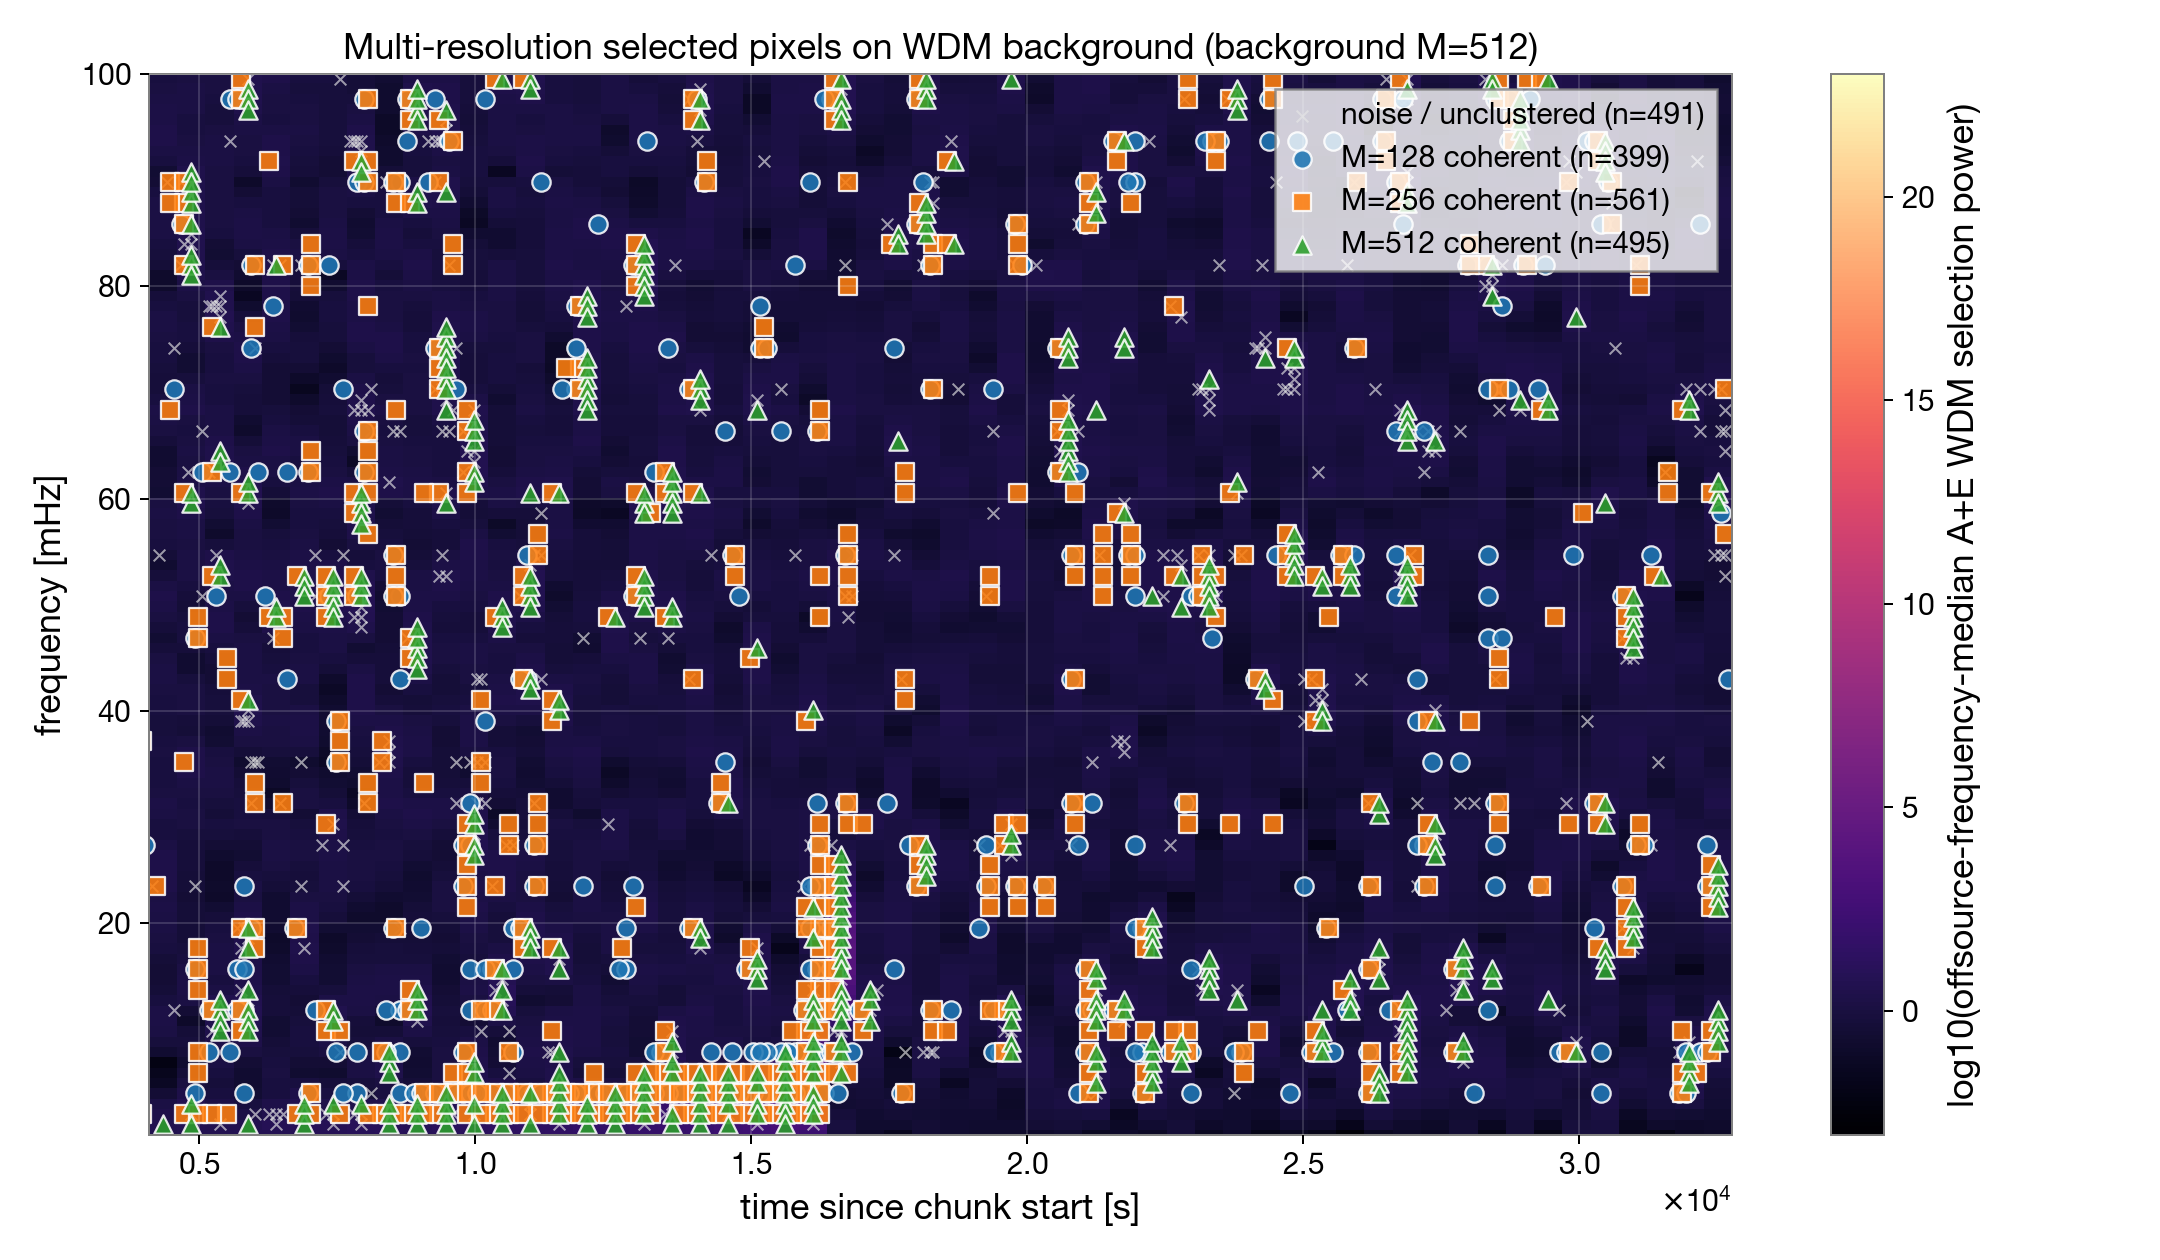

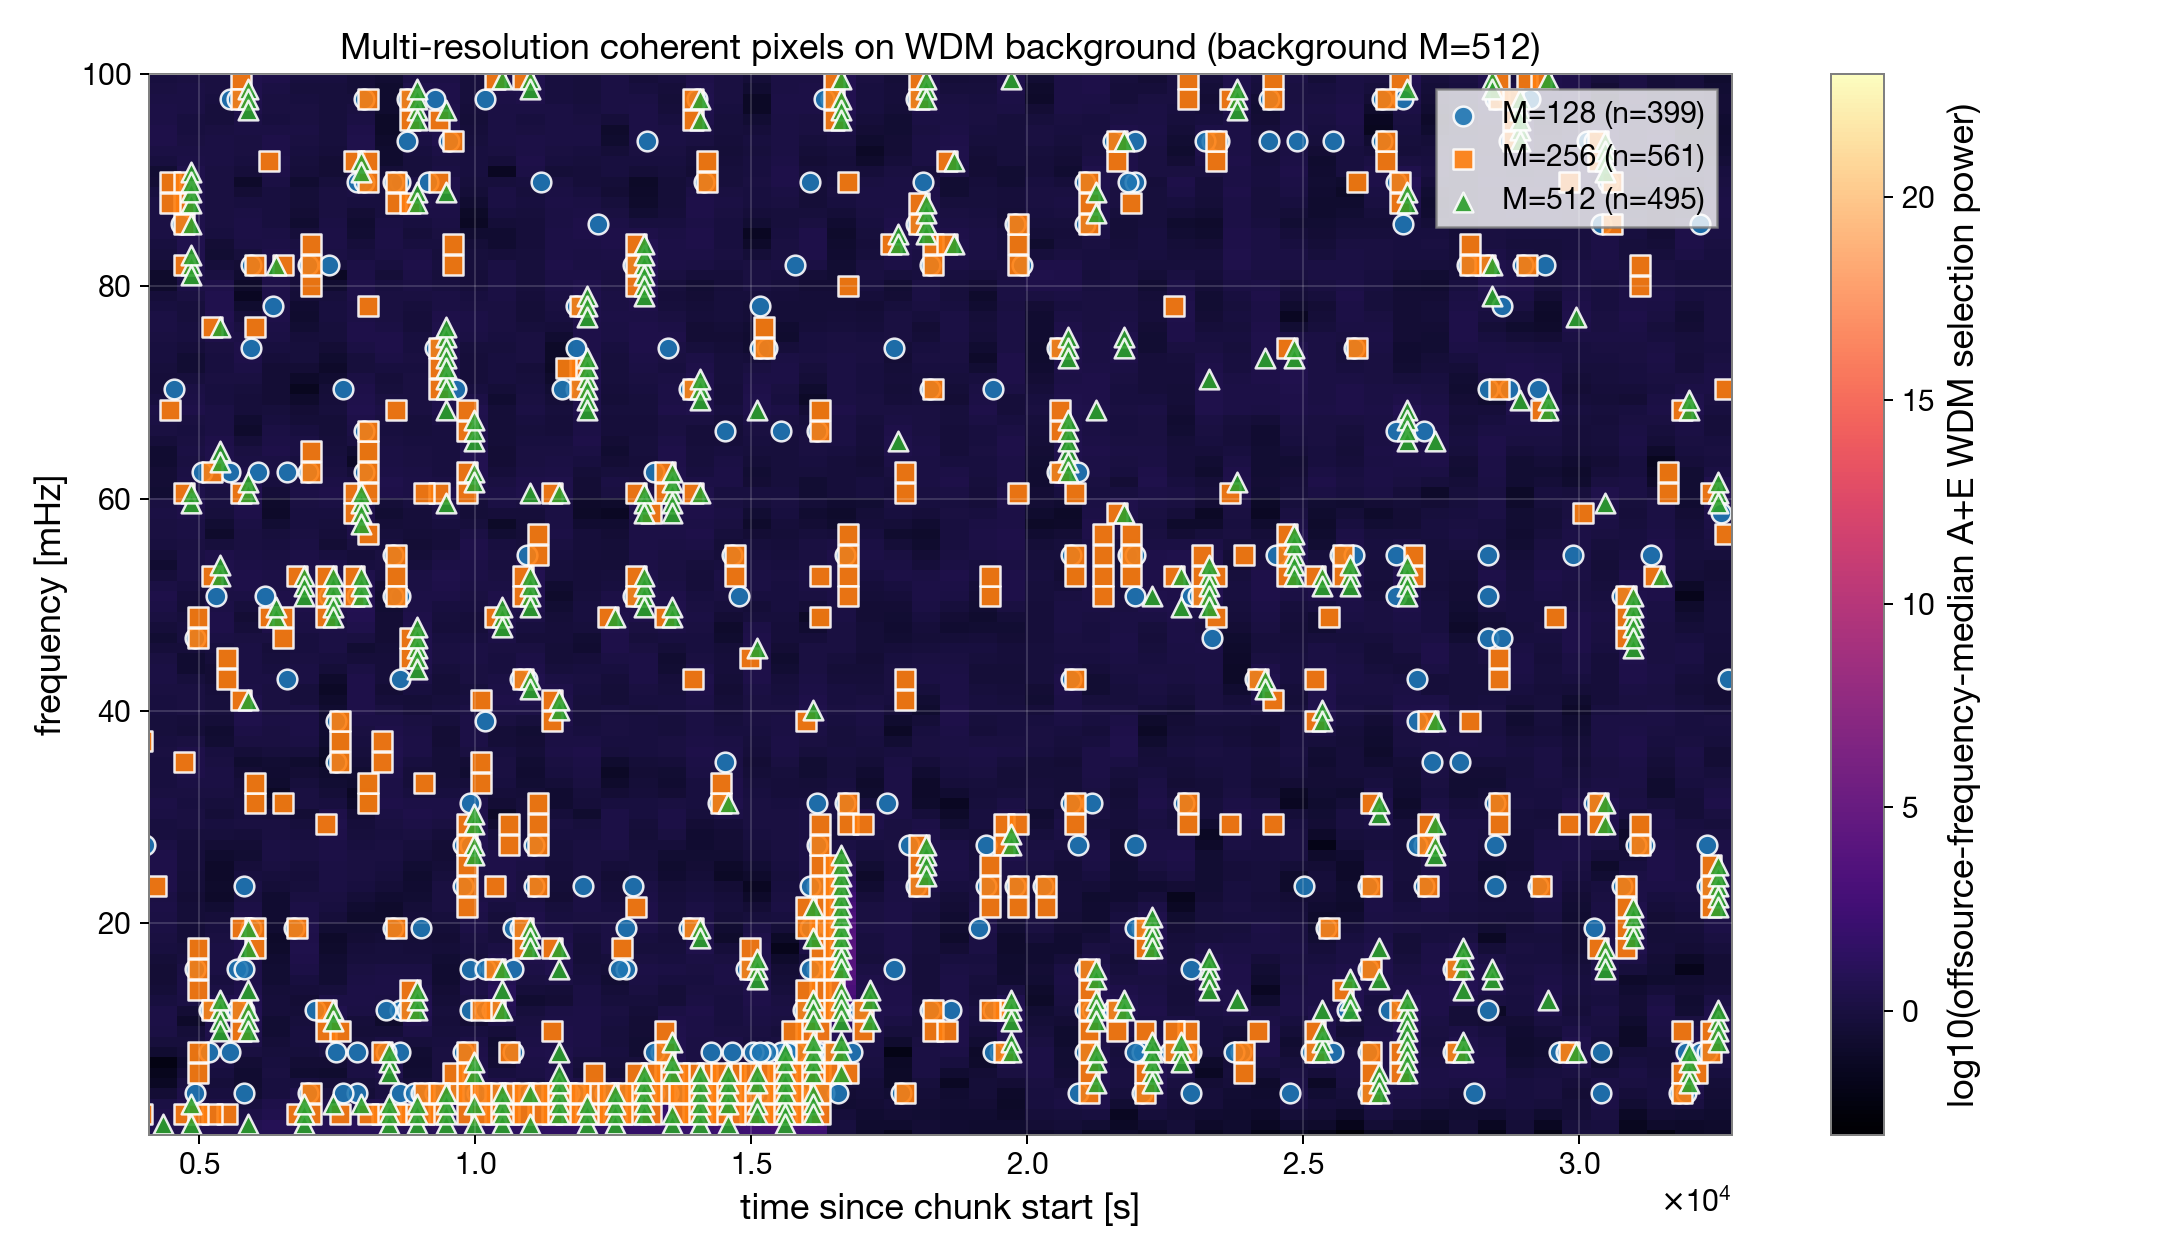

In [14]:
from IPython.display import Image, display
for name in [
    "plots/wdm_only_m_512_trim_start_4096s_end_0s_freq_0.01_to_100mHz.png",
    "plots/multires_selected_overlay_on_wdm_trim_start_4096s_end_0s_freq_0.01_to_100mHz.png",
    "plots/multires_coherent_overlay_on_wdm_trim_start_4096s_end_0s_freq_0.01_to_100mHz.png",
]:
    path = RUN_DIR / name
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print(f"Missing {path}")

## Practical Tuning Notes

- Increase `nside` for finer sky tagging after the low-resolution prototype works.
- Lower `top-pixel-fraction` if noisy WDM pixels dominate the kappa scan cost.
- Use `--skip-hdbscan` during kappa scans so HDBSCAN can be tuned cheaply afterward.
- For long tracks, HDBSCAN may split one source into multiple event fragments; the cross-resolution merge is a first mitigation, not the final long-duration tracker.
- The current kappa calculation uses a static equilateral constellation approximation. Treat localization as a coherence tag until the time-dependent constellation response is added.